# Diseño 3D en estrella para un óvalo pequeño

Este notebook explica **cómo funciona** el diseño de adquisición en estrella para estudiar en 3D el subsuelo de un óvalo de ~5 m de largo hasta ~10 m de profundidad. No invierte datos: simula la geometría y los rayos para ver **qué parte del subsuelo cubre cada parte del diseño**.

Idea central:
1. **Profundidad**: en refracción, un rayo llega más hondo cuanto mayor es la distancia fuente–geófono (offset). Para 10 m hacen falta offsets de varias decenas de metros, por eso las líneas salen del óvalo.
2. **3D**: una sola línea solo ve el subsuelo en un plano vertical. Varias líneas cruzadas y los **disparos cruzados** (disparar desde otra línea mientras se registra una) hacen que bajo el óvalo pasen rayos en muchas direcciones.

**Supuesto**: velocidad que aumenta linealmente con la profundidad, $V(z) = V_0 + g\,z$, con valores parecidos a L1. Es un modelo ilustrativo; con capas bruscas la geometría de rayos cambia, pero las conclusiones de diseño son las mismas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Ellipse
%matplotlib inline

# --- Sitio ---
OVAL_A, OVAL_B = 2.5, 1.5      # m, semiejes del óvalo (5 m x 3 m)
TARGET_DEPTH = 10.0            # m

# --- Diseño en estrella ---
LINE_AZIMUTHS = [0, 45, 90, 135]   # grados
INNER_HALF, INNER_DX = 5.0, 1.0    # geófonos cada 1 m entre -5 y +5 m
OUTER_HALF, OUTER_DX = 20.0, 2.5   # y cada 2.5 m hasta +-20 m (línea de 40 m)
INLINE_SHOTS = [-27.5, -20, -15, -10, -5, 0, 5, 10, 15, 20, 27.5]  # m sobre la línea
CROSS_SHOTS = [-27.5, 27.5]        # posiciones de las OTRAS líneas usadas como disparos cruzados
HITS_PER_SHOT = 8

LINE_AZIMUTHS_6 = [0, 30, 60, 90, 120, 150]  # variante con 6 líneas

# --- Modelo de velocidad ilustrativo (parecido a L1) ---
V0, GRAD = 500.0, 70.0             # m/s y 1/s  ->  V(10 m) = 1200 m/s

EARTH = ["#eadbb8", "#c8a06e", "#8c6a4a", "#5a3d26"]

## 1. Geometría

Cada línea es un tendido de 24 canales:
- **23 geófonos**: cada 1 m dentro y cerca del óvalo (detalle somero) y cada 2.5 m hacia afuera (alcance en profundidad).
- **Canal 24**: geófono junto a la fuente como referencia de tiempo del trigger.

Se registra **una línea a la vez**. Para cada línea se dispara:
- **en línea**: en los extremos, cada 5 m, en el centro y 7.5 m más allá de cada extremo;
- **cruzados**: desde los puntos extremos (±27.5 m) de las otras tres líneas.

In [2]:
inner = np.arange(-INNER_HALF, INNER_HALF + 1e-9, INNER_DX)
outer = np.arange(INNER_HALF + OUTER_DX, OUTER_HALF + 1e-9, OUTER_DX)
offsets_along = np.sort(np.r_[-outer, inner, outer])

def along_line(az, d):
    a = np.deg2rad(az)
    return np.c_[np.asarray(d) * np.cos(a), np.asarray(d) * np.sin(a)]

def build_lines(azimuths):
    out = {}
    for az in azimuths:
        cross = [along_line(other, CROSS_SHOTS) for other in azimuths if other != az]
        cross = np.vstack(cross) if cross else np.empty((0, 2))
        out[az] = {"geophones": along_line(az, offsets_along),
                   "inline": along_line(az, INLINE_SHOTS),
                   "cross": cross}
    return out

lines = build_lines(LINE_AZIMUTHS)

n_geo = len(offsets_along)
n_in, n_cross = len(INLINE_SHOTS), len(lines[LINE_AZIMUTHS[0]]["cross"])
plan = pd.DataFrame([{
    "línea": f"{az}°", "geófonos": n_geo, "disparos en línea": n_in, "disparos cruzados": n_cross,
    "golpes": (n_in + n_cross) * HITS_PER_SHOT, "trazas": (n_in + n_cross) * n_geo,
} for az in LINE_AZIMUTHS])
plan = plan.set_index("línea")
plan.loc["total"] = plan.sum()
plan

,geófonos,disparos en línea,disparos cruzados,golpes,trazas
línea,,,,,
0°,23,11,6,136,391
45°,23,11,6,136,391
90°,23,11,6,136,391
135°,23,11,6,136,391
total,92,44,24,544,1564


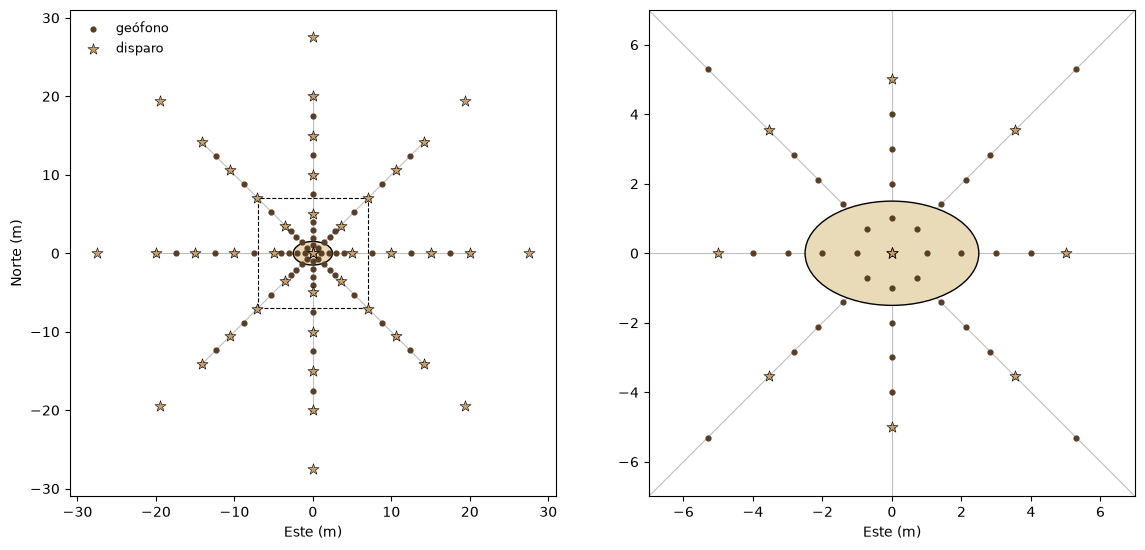

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [1.25, 1]})
for ax, lim in zip(axes, (31, 7)):
    for az, L in lines.items():
        g = L["geophones"]
        ax.plot(g[:, 0], g[:, 1], color="0.75", lw=0.8, zorder=1)
        ax.scatter(g[:, 0], g[:, 1], s=12, color=EARTH[3], zorder=3)
        ax.scatter(L["inline"][:, 0], L["inline"][:, 1], marker="*", s=70,
                   color=EARTH[1], ec="k", lw=0.4, zorder=4)
    ax.add_patch(Ellipse((0, 0), 2 * OVAL_A, 2 * OVAL_B, fc=EARTH[0], ec="k", lw=1, zorder=2))
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel("Este (m)")
axes[0].set_ylabel("Norte (m)")
axes[0].scatter([], [], s=12, color=EARTH[3], label="geófono")
axes[0].scatter([], [], marker="*", s=70, color=EARTH[1], ec="k", lw=0.4, label="disparo")
axes[0].legend(loc="upper left", frameon=False, fontsize=9)
axes[0].add_patch(plt.Rectangle((-7, -7), 14, 14, fill=False, ls="--", lw=0.8))
plt.tight_layout(); plt.show()

A la izquierda está el diseño completo y a la derecha el zoom sobre el óvalo. Las 4 líneas comparten el centro, y cerca del óvalo los geófonos están cada 1 m.

## 2. ¿Hasta qué profundidad llega cada rayo?

Si $V(z) = V_0 + g z$, el rayo entre una fuente y un geófono separados $X$ es un **arco de círculo**. Su punto más profundo está a mitad de camino:

$$z_{max}(X) = \frac{V_0}{g}\left(\sqrt{1 + \left(\frac{g X}{2 V_0}\right)^2} - 1\right)$$

Por eso **los offsets cortos ven la parte somera y los largos la profunda**: el óvalo (5 m) por sí solo no alcanza los 10 m.

Offset necesario para que el rayo llegue a 10 m: 31 m
Un tendido de 5 m (solo el óvalo) llega a 0.4 m


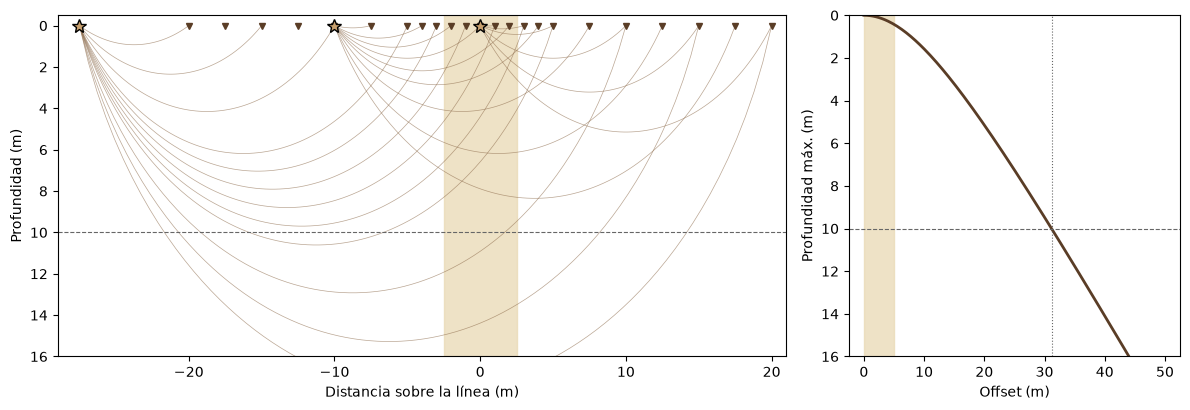

In [4]:
h = V0 / GRAD

def turning_depth(X):
    return h * (np.sqrt(1 + (GRAD * np.asarray(X) / (2 * V0)) ** 2) - 1)

def ray_depth(s, X):
    """Profundidad del rayo a la distancia s desde la fuente (0 <= s <= X)."""
    R = np.sqrt((X / 2) ** 2 + h ** 2)
    return np.clip(np.sqrt(np.maximum(R ** 2 - (s - X / 2) ** 2, 0)) - h, 0, None)

X_needed = 2 * h * np.sqrt(((TARGET_DEPTH + h) / h) ** 2 - 1)
print(f"Offset necesario para que el rayo llegue a {TARGET_DEPTH:.0f} m: {X_needed:.0f} m")
print(f"Un tendido de 5 m (solo el óvalo) llega a {turning_depth(5):.1f} m")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
geo = offsets_along
for sx in (-27.5, -10, 0):
    for gx in geo[geo > sx][::2]:
        X = gx - sx
        s = np.linspace(0, X, 80)
        ax1.plot(sx + s, ray_depth(s, X), color=EARTH[2], lw=0.5, alpha=0.6)
ax1.plot(geo, np.zeros_like(geo), "v", color=EARTH[3], ms=4)
ax1.plot([-27.5, -10, 0], [0, 0, 0], "*", color=EARTH[1], mec="k", ms=10)
ax1.axvspan(-OVAL_A, OVAL_A, color=EARTH[0], alpha=0.8, zorder=0)
ax1.axhline(TARGET_DEPTH, color="0.4", ls="--", lw=0.8)
ax1.set_ylim(16, -0.5); ax1.set_xlim(-29, 21)
ax1.set_xlabel("Distancia sobre la línea (m)"); ax1.set_ylabel("Profundidad (m)")

X = np.linspace(0, 50, 200)
ax2.plot(X, turning_depth(X), color=EARTH[3], lw=2)
ax2.axhline(TARGET_DEPTH, color="0.4", ls="--", lw=0.8)
ax2.axvline(X_needed, color="0.4", ls=":", lw=0.8)
ax2.axvspan(0, 2 * OVAL_A, color=EARTH[0], alpha=0.8)
ax2.set_ylim(16, 0); ax2.set_xlabel("Offset (m)"); ax2.set_ylabel("Profundidad máx. (m)")
plt.tight_layout(); plt.show()

Izquierda: rayos de tres disparos de una línea; la franja clara es el óvalo y la línea discontinua los 10 m. Los rayos que pasan bajo el óvalo a 10 m vienen de disparos lejanos, fuera del óvalo. Derecha: profundidad máxima frente al offset.

## 3. Cómo se forma el 3D: los disparos cruzados

En planta, cada rayo va en línea recta de la fuente al geófono y a lo largo del camino baja como el arco anterior. Para resolver el 3D bajo el óvalo no basta con que pasen muchos rayos: deben pasar **en varias direcciones**. Si todos van en una dirección, el modelo no puede saber si una anomalía está a un lado o al otro.

Comparamos cuatro diseños:
- **1 línea (2D)**, como L1;
- **4 líneas sin disparos cruzados**;
- **4 líneas con disparos cruzados** (el diseño de la sección 1);
- **6 líneas con disparos cruzados** (cada 30°).

Para cada celda de 2 × 2 × 1 m se cuentan los rayos que la cruzan y cuántas **direcciones distintas** tienen (sectores de 45°: 0–4). Se usan celdas de 2 m porque a ~40 Hz la longitud de onda es de ~25 m, y una tomografía 3D no resuelve detalles laterales mucho menores. Un rayo dibujado como una línea fina es solo una aproximación.

In [5]:
DXY, DZ = 2.0, 1.0
xe = np.arange(-26, 26 + DXY, DXY); ze = np.arange(0, 15 + DZ, DZ)
nx, nz = len(xe) - 1, len(ze) - 1

def coverage(rays):
    count = np.zeros((nx, nx, nz), int)
    dirs = np.zeros((nx, nx, nz, 4), bool)
    for S, Rcv in rays:
        X = np.hypot(*(Rcv - S))
        s = np.linspace(0, X, max(int(X / 0.2), 2))
        p = S + np.outer(s / X, Rcv - S)
        ix = np.digitize(p[:, 0], xe) - 1; iy = np.digitize(p[:, 1], xe) - 1
        iz = np.digitize(ray_depth(s, X), ze) - 1
        ok = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < nx) & (iz >= 0) & (iz < nz)
        cells = np.unique(np.c_[ix, iy, iz][ok], axis=0).T
        az = int((np.degrees(np.arctan2(*(Rcv - S)[::-1])) % 180 + 22.5) // 45) % 4
        count[tuple(cells)] += 1
        dirs[(*cells, np.full(cells.shape[1], az))] = True
    return count, dirs.sum(axis=-1)

def rays_for(azimuths, use_cross):
    rays = []
    for az, L in build_lines(azimuths).items():
        shots = np.vstack([L["inline"], L["cross"]]) if use_cross else L["inline"]
        rays += [(s, g) for s in shots for g in L["geophones"] if np.hypot(*(g - s)) > 0.5]
    return rays

designs = {
    "1 línea (2D)": rays_for([0], False),
    "4 líneas sin cruzados": rays_for(LINE_AZIMUTHS, False),
    "4 líneas con cruzados": rays_for(LINE_AZIMUTHS, True),
    "6 líneas con cruzados": rays_for(LINE_AZIMUTHS_6, True),
}
results = {name: coverage(r) for name, r in designs.items()}

xc = (xe[:-1] + xe[1:]) / 2
XX, YY = np.meshgrid(xc, xc, indexing="ij")
R = np.hypot(XX, YY)
near, wide = R <= 4, R <= 8   # cilindros bajo el óvalo (r <= 4 m) y alrededor (r <= 8 m)

rows = []
for name, (cnt, nd) in results.items():
    row = {"diseño": name, "rayos": len(designs[name])}
    for z0, z1 in ((0, 3), (3, 7), (7, 10)):
        k = slice(int(z0 / DZ), int(z1 / DZ))
        row[f"r≤4 m, {z0}–{z1} m"] = round(100 * (nd[near][:, k] >= 3).mean())
        row[f"r≤8 m, {z0}–{z1} m"] = round(100 * (nd[wide][:, k] >= 3).mean())
    rows.append(row)
summary = pd.DataFrame(rows).set_index("diseño")
print("% de celdas cruzadas por rayos en >= 3 direcciones")
summary

% de celdas cruzadas por rayos en >= 3 direcciones


,rayos,"r≤4 m, 0–3 m","r≤8 m, 0–3 m","r≤4 m, 3–7 m","r≤8 m, 3–7 m","r≤4 m, 7–10 m","r≤8 m, 7–10 m"
diseño,,,,,,,
1 línea (2D),244,0,0,0,0,0,0
4 líneas sin cruzados,976,8,2,10,2,8,2
4 líneas con cruzados,1528,100,74,94,89,19,63
6 líneas con cruzados,2844,100,97,100,100,75,94


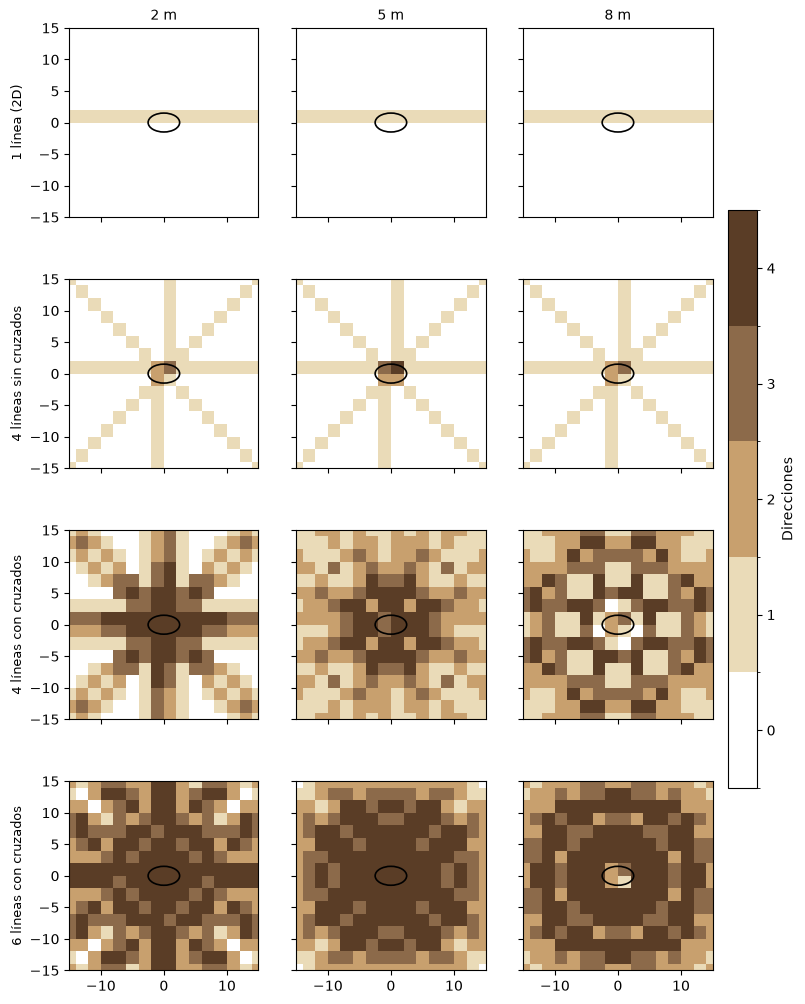

In [6]:
cmap = ListedColormap(["white"] + EARTH)
norm = BoundaryNorm(np.arange(-0.5, 5), cmap.N)
depths = [2, 5, 8]
fig, axes = plt.subplots(4, 3, figsize=(10, 12.5), sharex=True, sharey=True)
for r, (name, (cnt, nd)) in enumerate(results.items()):
    for c, z in enumerate(depths):
        ax = axes[r, c]
        im = ax.pcolormesh(xe, xe, nd[:, :, int(z / DZ)].T, cmap=cmap, norm=norm)
        ax.add_patch(Ellipse((0, 0), 2 * OVAL_A, 2 * OVAL_B, fill=False, ec="k", lw=1.2))
        ax.set_aspect("equal"); ax.set_xlim(-15, 15); ax.set_ylim(-15, 15)
        if r == 0: ax.set_title(f"{z} m", fontsize=10)
        if c == 0: ax.set_ylabel(name, fontsize=9)
cb = fig.colorbar(im, ax=axes, shrink=0.6, ticks=range(5), pad=0.02)
cb.set_label("Direcciones")
plt.show()

Cada fila es un diseño y cada columna una profundidad (vista en planta, ±15 m alrededor del óvalo). El color indica cuántas direcciones distintas de rayos cruzan cada celda: blanco = ninguna, marrón oscuro = 4.

Cómo leerlo (los porcentajes están en la tabla anterior):
- **1 línea**: solo ve una franja estrecha y en una dirección. No distingue lo que hay a los lados: es 2D.
- **4 líneas sin cruzados**: la cobertura queda sobre las propias líneas y entre ellas quedan huecos. Casi ninguna celda tiene 3 direcciones.
- **4 líneas con cruzados**: los disparos desde las otras líneas generan rayos oblicuos que llenan los huecos. Bajo el óvalo hay 3 o más direcciones casi en todas partes entre 0 y 7 m, pero **entre 7 y 10 m, justo debajo, la cobertura es incompleta**.
- **6 líneas con cruzados**: casi duplica el trabajo de campo, pero completa la cobertura profunda bajo el óvalo. **Recomendable si lo importante es 7–10 m.**

Los disparos cruzados son lo que convierte la estrella en un levantamiento 3D. Añadir líneas mejora sobre todo la parte profunda.

## 4. Vista 3D de los rayos cruzados

Rayos de los disparos cruzados registrados en la línea de 0°. Pasan bajo el óvalo desde direcciones oblicuas y a varias profundidades.

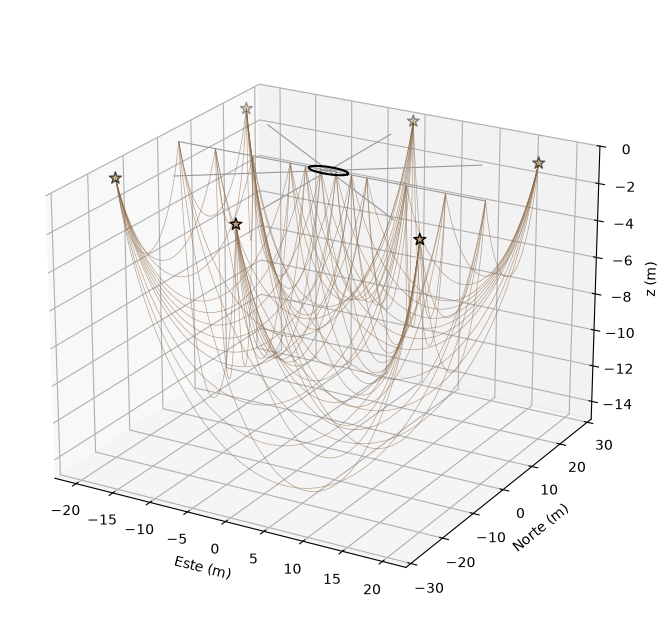

In [7]:
fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(projection="3d")
L = lines[0]
for S in L["cross"]:
    for G in L["geophones"][::2]:
        X = np.hypot(*(G - S)); s = np.linspace(0, X, 60)
        p = S + np.outer(s / X, G - S)
        ax.plot(p[:, 0], p[:, 1], -ray_depth(s, X), color=EARTH[2], lw=0.5, alpha=0.6)
for az, Lk in lines.items():
    g = Lk["geophones"]; ax.plot(g[:, 0], g[:, 1], 0, color="0.6", lw=0.8)
ax.scatter(L["cross"][:, 0], L["cross"][:, 1], 0, marker="*", s=80, color=EARTH[1], ec="k")
t = np.linspace(0, 2 * np.pi, 60)
ax.plot(OVAL_A * np.cos(t), OVAL_B * np.sin(t), 0, color="k", lw=1.5)
ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)"); ax.set_zlabel("z (m)")
ax.set_zlim(-15, 0); ax.view_init(elev=22, azim=-60)
plt.tight_layout(); plt.show()

## 5. Procedimiento en campo

1. **Replanteo**: marca el centro del óvalo y las 4 direcciones (0°, 45°, 90°, 135°). Mide **x, y, z** de cada geófono y punto de disparo (GPS RTK o estación total, precisión de centímetros).
2. **Prueba del trigger**: haz 5 golpes en el mismo punto y comprueba que las primeras llegadas coinciden a mejor de 0.25 ms. Deja el canal 24 junto a la fuente como referencia.
3. **Por cada línea** (una a la vez, 24 canales):
   1. Planta los 23 geófonos con buen acople al suelo.
   2. Haz los 11 disparos en línea, de un extremo al otro.
   3. Haz los 6 disparos cruzados en los puntos ±27.5 m de las otras tres líneas.
   4. Da 8 golpes por posición, **guarda cada golpe** por separado y también el apilado.
   5. Revisa en pantalla que se vean las primeras llegadas lejanas; si no, añade golpes.
4. **Nombres de archivo**: `linea_azimut_disparo_posicion_golpe` (por ejemplo `L045_S-27.5_h03.dat`), y una bitácora con hora, posición y observaciones.
5. **Control**: repite al final 1–2 disparos de la primera línea para comprobar que el sistema no cambió.

Los totales de geófonos, disparos, golpes y trazas del diseño de 4 líneas están en la tabla de la sección 1. Con 6 líneas cada una lleva 10 disparos cruzados (21 posiciones por línea).

## 6. Limitaciones

- El modelo de gradiente es ilustrativo. Con contactos bruscos los rayos viajan por la interfaz (head waves), pero la regla "offset largo = más profundo" se mantiene.
- La refracción **no detecta capas lentas debajo de capas rápidas**. Para eso, combínala con downhole o MASW.
- La inversión 3D de estos datos puede hacerse con pyGIMLi, que necesita `tetgen` para mallas 3D o una malla regular. Refrapy solo trabaja en 2D.
- Cambia los parámetros de la primera celda (tamaño del óvalo, offsets, número de líneas, `V0`, `GRAD`) para adaptar el diseño a otro sitio.